# Part 3 — Large visual vocabularies vs compact vocabularies with PCA

**Protocolo:** exclusivamente `train`, com cross-validation por imagem (5 folds × 3 seeds), estratificada por categoria (aproximadamente quando existem imagens multi-label). Não é usado `val` nem `test`. As cinco categorias são avaliadas one-vs-background com SVM linear; métricas agregadas em mAP. O codebook BoVW é treinado novamente *dentro de cada fold*, e PCA e SVM são ajustados exclusivamente no subconjunto de treino desse fold.

**Comparações:** (A) vocabulário pequeno, (B) grande, (C) grande + PCA, (D) pequeno com dimensão igual à saída de PCA. Recolhem-se mAP, AP por classe, accuracy, macro-F1, tamanho dos vetores, custo de aprendizagem do vocabulário, codificação, PCA, SVM, inferência e memória. Os resultados de VLAD/FV da Part 1/2 são apenas uma **referência complementar** quando obtidos a partir de descritores pré-computados: podem não respeitar o mesmo isolamento do codebook por fold.

**Execução:** colocar o notebook na raiz do projeto (com `src/`, `data/splits/`, `data/images/` e `data/encodings/`). O treino de 5×3 folds para todos os codebooks é computacionalmente dispendioso; o cache reduz reexecuções, preservando as medições originais. Não se criam resultados fictícios.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import platform
import json
import hashlib
import joblib
import cv2
import warnings
from pathlib import Path
from time import perf_counter
from inspect import signature
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, accuracy_score, f1_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display
from src import utils
from src.features import computeFeatures

PART3_ROOT = Path("data")
PART3_OUTPUT = Path("results/part3_complete")
PART3_CACHE = PART3_OUTPUT / "cache"
PART3_CATEGORIES = ("motorbike", "aeroplane", "person", "horse", "car")
PART3_SEEDS = (42, 43, 44)
PART3_DIMS = (128, 256)
PART3_N_FOLDS = 5
PART3_C = 10.0
PART3_SAMPLE_IMAGES_PER_CLASS = 100
PART3_SAMPLE_DESCRIPTORS = 128
PART3_MAX_DESCRIPTORS = 2000
PART3_METHODS = {"bovw": (128, 256, 512, 1024)}
SVM_DEFAULTS = signature(utils.train_svm).parameters
SVM_MAX_ITER = 200_000  # coerente com Part 1/2; evita parar cedo nos dados de alta dimensão
SVM_TOL = SVM_DEFAULTS["tol"].default
SVM_SEED = SVM_DEFAULTS["seed"].default
PART3_VERSION = "bovw-cv5-multilabel-v3"
PART3_OUTPUT.mkdir(parents=True, exist_ok=True)
PART3_CACHE.mkdir(parents=True, exist_ok=True)

part3_environment = {"python": platform.python_version(), "numpy": np.__version__,
    "sklearn": sklearn.__version__, "platform": platform.platform(),
    "processor": platform.processor(), "C": PART3_C,
    "svm_max_iter": SVM_MAX_ITER, "svm_tol": SVM_TOL, "svm_seed": SVM_SEED,
    "seeds": PART3_SEEDS, "methods": PART3_METHODS,
    "sample_images_per_class": PART3_SAMPLE_IMAGES_PER_CLASS,
    "sample_descriptors_per_image": PART3_SAMPLE_DESCRIPTORS,
    "max_descriptors_per_image": PART3_MAX_DESCRIPTORS,
    "evaluation": "train-only repeated 5-fold CV, multi-label-aware; NO test/val evaluation",
    "folds": PART3_N_FOLDS,
    "version": PART3_VERSION}
display(part3_environment)
(PART3_OUTPUT / "environment.json").write_text(
    json.dumps(part3_environment, ensure_ascii=False, indent=2), encoding="utf-8")


{'python': '3.11.18',
 'numpy': '2.4.6',
 'sklearn': '1.9.1',
 'platform': 'Windows-10-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 186 Stepping 2, GenuineIntel',
 'C': 10.0,
 'svm_max_iter': 200000,
 'svm_tol': 0.0001,
 'svm_seed': 42,
 'seeds': (42, 43, 44),
 'methods': {'bovw': (128, 256, 512, 1024)},
 'sample_images_per_class': 100,
 'sample_descriptors_per_image': 128,
 'max_descriptors_per_image': 2000,
 'evaluation': 'train-only repeated 5-fold CV, multi-label-aware; NO test/val evaluation',
 'folds': 5,
 'version': 'bovw-cv5-multilabel-v3'}

638

## Stage A — Dados de treino e folds

Usa apenas o split `train`. Os folds são definidos por identificador único de imagem, iguais em todas as configurações. Se uma imagem aparecer em várias categorias, as suas anotações são preservadas e aplica-se estratificação multi-label aproximada; sem sobreposições, usa-se StratifiedKFold. A preparação de SIFT e o limite de 2000 descritores por imagem seguem o notebook original.

In [4]:
def l2norm(x):
    return x / (np.sqrt(np.sum(x**2, axis=-1, keepdims=True)) + 1e-10)


def cacheKey(*values):
    text = json.dumps(values, sort_keys=True, default=str)
    return hashlib.sha256(text.encode()).hexdigest()[:24]


part3_train_table = utils.loadSamplesTable(PART3_ROOT / "splits", PART3_ROOT / "images", subset="train")
part3_allowed = (*PART3_CATEGORIES, "background")
part3_train_table = part3_train_table[part3_train_table.category.isin(part3_allowed)].copy()
for category in part3_allowed:
    if (part3_train_table.category == category).sum() < PART3_N_FOLDS:
        raise ValueError(f"São necessárias >= {PART3_N_FOLDS} imagens na classe {category}")
if part3_train_table.duplicated(["filename", "category"]).any():
    raise ValueError("Imagens repetidas na mesma categoria")
# O dataset admite imagens com várias categorias (multi-label). A identidade
# da imagem é filename; NÃO exigir que cada imagem tenha uma só categoria.
# Uma mesma imagem nunca pode ser usada em dois folds distintos.
path_counts = part3_train_table.groupby("filename")["filepath"].nunique()
if (path_counts > 1).any():
    conflicting = path_counts[path_counts > 1].index[:5].tolist()
    raise ValueError(f"Mesmo filename com caminhos diferentes (verificar IDs): {conflicting}")
# Positivos e background são mutuamente exclusivos na avaliação binária.
targets = part3_train_table[part3_train_table.category.isin(PART3_CATEGORIES)]
bg_names = set(part3_train_table.loc[part3_train_table.category.eq("background"), "filename"])
ambiguous = bg_names.intersection(targets.filename)
if ambiguous:
    raise ValueError(f"Existem imagens anotadas como background e positivas: {sorted(ambiguous)[:5]}")
part3_train_images = (part3_train_table.drop_duplicates("filename")
                      .sort_values("filename").reset_index(drop=True))
part3_membership = (pd.crosstab(part3_train_table.filename, part3_train_table.category)
                    .reindex(index=part3_train_images.filename, columns=part3_allowed,
                             fill_value=0).gt(0).astype(np.int8))
part3_label_matrix = part3_membership.to_numpy(dtype=np.int8)
if not part3_label_matrix.any(axis=1).all():
    raise ValueError("Existem imagens sem nenhuma categoria válida")
part3_multilabel_count = int((part3_label_matrix.sum(axis=1) > 1).sum())
part3_stats = part3_train_table.groupby("category").size().rename("train_count").to_frame()
display(part3_stats)
print(f"Imagens distintas: {len(part3_train_images)}; com várias categorias: {part3_multilabel_count}.")
print(f"Protocolo: apenas train; {PART3_N_FOLDS}-fold CV; seeds={PART3_SEEDS}. Sem val/test.")

def localFeatures(row):
    path = Path(row.filepath)
    key = cacheKey(PART3_VERSION, str(path.resolve()), path.stat().st_mtime_ns,
                   PART3_MAX_DESCRIPTORS)
    output = PART3_CACHE / f"sift_{key}.npz"
    if output.exists():
        with np.load(output) as data:
            return data["descriptors"], float(data["extraction_s"])
    started = perf_counter()
    # Leitura compatível com caminhos Unicode no Windows.
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Não foi possível ler {path}")
    _, descriptors, _ = computeFeatures(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    extraction_seconds = perf_counter() - started
    if PART3_MAX_DESCRIPTORS and len(descriptors) > PART3_MAX_DESCRIPTORS:
        indices = np.linspace(0, len(descriptors)-1, PART3_MAX_DESCRIPTORS, dtype=int)
        descriptors = descriptors[indices]
    descriptors = np.asarray(descriptors, dtype=np.float32)
    if not len(descriptors):
        raise ValueError(f"Imagem sem descritores: {path}")
    np.savez_compressed(output, descriptors=descriptors, extraction_s=extraction_seconds)
    return descriptors, extraction_seconds


def sampleLocalFeatures(table, seed):
    rng = np.random.default_rng(seed)
    chosen = []
    for _, rows in table.groupby("category"):
        chosen.extend(rng.choice(rows.filename.unique(),
                      min(PART3_SAMPLE_IMAGES_PER_CLASS, rows.filename.nunique()), replace=False))
    images = table[table.filename.isin(chosen)].drop_duplicates("filename").sort_values("filename")
    samples = []
    for row in images.itertuples():
        descriptors, _ = localFeatures(row)
        indices = rng.choice(len(descriptors), min(PART3_SAMPLE_DESCRIPTORS, len(descriptors)), replace=False)
        samples.append(descriptors[indices])
    return np.vstack(samples)


,train_count
category,
aeroplane,112
background,1019
car,376
horse,139
motorbike,120
person,1025


Imagens distintas: 2472; com várias categorias: 300.
Protocolo: apenas train; 5-fold CV; seeds=(42, 43, 44). Sem val/test.


## Stage B: Vocabulários e encodings

BoVW usa MiniBatchKMeans, uma aproximação de k-means, sobre SIFT. Cada imagem é representada por um histograma global com K dimensões, normalizado em L2.

Amostragem e aprendizagem são medidas separadamente. Os tempos guardados no cache são os da construção original, não o tempo de leitura de um resultado já calculado.


In [5]:
def fitEncoder(table, method, k, seed):
    names = sorted(table.filename.unique())
    key = cacheKey(PART3_VERSION, method, k, seed, names,
                   PART3_SAMPLE_IMAGES_PER_CLASS,
                   PART3_SAMPLE_DESCRIPTORS, PART3_MAX_DESCRIPTORS)
    path = PART3_CACHE / f"encoder_{key}.joblib"
    if path.exists():
        bundle = joblib.load(path)
        bundle["encoder_file_KiB"] = path.stat().st_size / 1024
        return bundle
    started = perf_counter()
    descriptors = sampleLocalFeatures(table, seed)
    sample_seconds = perf_counter() - started
    started = perf_counter()
    model = MiniBatchKMeans(n_clusters=k, batch_size=4096, n_init=3,
                            max_iter=200, random_state=seed)
    model.fit(descriptors)
    fit_seconds = perf_counter() - started
    bundle = {"key": key, "method": method, "K": k, "model": model,
              "sample_s": sample_seconds,
              "codebook_fit_s": fit_seconds,
              "train_names": names, "encoder_converged": bool(model.n_iter_ < model.max_iter)}
    joblib.dump(bundle, path)
    bundle["encoder_file_KiB"] = path.stat().st_size / 1024
    joblib.dump(bundle, path)
    return bundle


def encodeDescriptors(descriptors, encoder):
    words = encoder["model"].predict(descriptors)
    histograms = np.bincount(words, minlength=encoder["K"]).astype(np.float64)
    return l2norm(histograms)


def encodeImages(images, encoder):
    key = cacheKey(encoder["key"], images.filename.tolist(),
                   [str(p) for p in images.filepath])
    path = PART3_CACHE / f"features_{key}.npz"
    if path.exists():
        with np.load(path) as data:
            return data["histograms"], float(data["sift_s"]), float(data["encoding_s"])
    histograms, sift_seconds, encoding_seconds = [], 0.0, 0.0
    for row in images.itertuples():
        descriptors, extraction_seconds = localFeatures(row)
        started = perf_counter()
        histograms.append(encodeDescriptors(descriptors, encoder))
        encoding_seconds += perf_counter() - started
        sift_seconds += extraction_seconds
    histograms = np.asarray(histograms, dtype=np.float64)
    np.savez_compressed(path, histograms=histograms, sift_s=sift_seconds,
                        encoding_s=encoding_seconds)
    return histograms, sift_seconds, encoding_seconds


def binarySubset(histograms, images, table, category):
    positives = set(table.loc[table.category == category, "filename"])
    negatives = set(table.loc[table.category == "background", "filename"])
    if positives.intersection(negatives):
        raise ValueError(f"Rótulos positivos/background sobrepostos: {category}")
    names = images.filename.to_numpy()
    indices = np.flatnonzero(np.isin(names, list(positives | negatives)))
    labels = np.where(np.isin(names[indices], list(positives)), 1, -1)
    if set(labels) != {-1, 1}:
        raise ValueError(f"Split sem ambas as classes: {category}")
    return histograms[indices], labels


## Stage C — PCA e classificação

PCA é ajustado exclusivamente com as imagens de treino em cada fold. Classificador LinearSVC com `C=10`, `max_iter=200000`, `tol` da função `utils.train_svm`, em coerência com a Part 1/2. `train_AP` e `AP` de cross-validation permitem analisar o gap de generalização. A inferência reportada inclui PCA (quando aplicável) + SVM; SIFT e encoding são medidos separadamente. Custos de codebook são partilhados entre categorias, enquanto custos totais de PCA e SVM somam os cinco classificadores.

In [6]:
def runExperiment(train_x, train_y, val_x, val_y, dimension, seed):
    original_dimension = train_x.shape[1]
    pca_fit_seconds = 0.0
    explained_variance = 1.0
    pca_bytes = 0
    if dimension:
        if not 0 < dimension < min(original_dimension, len(train_y)):
            raise ValueError("PCA deve reduzir a dimensão e não exceder N_treino - 1")
        pca = PCA(n_components=dimension, svd_solver="randomized", random_state=seed)
        started = perf_counter()
        pca.fit(train_x)
        pca_fit_seconds = perf_counter() - started
        explained_variance = pca.explained_variance_ratio_.sum()
        pca_bytes = pca.components_.nbytes + pca.mean_.nbytes
        started = perf_counter()
        train_features = l2norm(pca.transform(train_x))
        train_projection_seconds = perf_counter() - started
    else:
        train_features, train_projection_seconds = train_x, 0.0
    clf = LinearSVC(C=PART3_C, loss="hinge", dual=True,
                    max_iter=SVM_MAX_ITER, tol=SVM_TOL, random_state=SVM_SEED)
    started = perf_counter()
    with warnings.catch_warnings(record=True) as recorded:
        warnings.simplefilter("always", ConvergenceWarning)
        clf.fit(train_features, train_y)
    fit_seconds = perf_counter() - started
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in recorded)
    if not converged:
        print(f"SVM sem convergência: dimensão {original_dimension}, PCA={dimension}, seed={seed}")
    started = perf_counter()
    val_features = l2norm(pca.transform(val_x)) if dimension else val_x
    scores = clf.decision_function(val_features)
    inference_seconds = perf_counter() - started
    predictions = np.where(scores >= 0, 1, -1)
    tn, fp, fn, tp = confusion_matrix(val_y, predictions, labels=[-1, 1]).ravel()
    return {"AP": average_precision_score(val_y, scores),
        "accuracy": accuracy_score(val_y, predictions),
        "macro_F1": f1_score(val_y, predictions, average="macro", zero_division=0),
        "train_AP": average_precision_score(train_y, clf.decision_function(train_features)),
        "AP_gap_train_minus_cv": average_precision_score(train_y, clf.decision_function(train_features)) - average_precision_score(val_y, scores),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "original_dimensions": original_dimension, "dimensions": train_features.shape[1],
        "removed_pct": 100*(1-train_features.shape[1]/original_dimension),
        "explained_variance": explained_variance, "pca_fit_s": pca_fit_seconds,
        "train_projection_s": train_projection_seconds, "svm_fit_s": fit_seconds,
        "inference_ms_per_image": 1000*inference_seconds/len(val_y),
        "feature_KiB_float64": train_features.shape[1]*8/1024,
        "pca_model_KiB": pca_bytes/1024,
        "train_samples": len(train_y), "val_samples": len(val_y),
        "svm_model_KiB": (clf.coef_.nbytes+clf.intercept_.nbytes)/1024,
        "converged": converged, "svm_iterations": int(clf.n_iter_)}


def makeFolds(seed):
    """Folds por imagem; preserva a distribuição de categorias sobrepostas.

    Single-label: StratifiedKFold do scikit-learn.
    Multi-label: estratificação iterativa aproximada sem dependências externas,
    atribuindo primeiro rótulos menos frequentes aos folds com maior défice.
    """
    labels = part3_label_matrix.astype(np.int64)
    n_images, n_labels = labels.shape
    if part3_multilabel_count == 0:
        primary = np.argmax(labels, axis=1)
        splitter = StratifiedKFold(n_splits=PART3_N_FOLDS, shuffle=True,
                                 random_state=seed)
        folds = list(splitter.split(np.arange(n_images), primary))
    else:
        rng = np.random.default_rng(seed)
        fold_assign = np.full(n_images, -1, dtype=int)
        capacity = np.full(PART3_N_FOLDS, n_images // PART3_N_FOLDS, dtype=int)
        capacity[rng.permutation(PART3_N_FOLDS)[:n_images % PART3_N_FOLDS]] += 1
        desired = np.outer(capacity / n_images, labels.sum(axis=0).astype(float))
        remaining = capacity.copy()
        order = rng.permutation(n_images)
        rank = np.empty(n_images, dtype=int)
        rank[order] = np.arange(n_images)
        while (fold_assign < 0).any():
            todo = fold_assign < 0
            frequencies = labels[todo].sum(axis=0)
            present = np.flatnonzero(frequencies > 0)
            if len(present) == 0:
                raise RuntimeError("Imagem sem classe durante a estratificação")
            rarest = present[frequencies[present] == frequencies[present].min()]
            label = int(rng.choice(rarest))
            candidates = np.flatnonzero(todo & labels[:, label].astype(bool))
            # Dar preferência a imagens com mais categorias, que são mais difíceis de equilibrar.
            candidates = sorted(candidates, key=lambda i: (-int(labels[i].sum()), int(rank[i])))
            for ix in candidates:
                available = np.flatnonzero(remaining > 0)
                best = available[np.isclose(desired[available, label],
                                           desired[available, label].max())]
                if len(best) > 1:
                    need = desired[best][:, labels[ix].astype(bool)].sum(axis=1)
                    best = best[np.isclose(need, need.max())]
                if len(best) > 1:
                    best = best[remaining[best] == remaining[best].max()]
                selected = int(rng.choice(best))
                fold_assign[ix] = selected
                remaining[selected] -= 1
                desired[selected] -= labels[ix]
        assert np.all(remaining == 0) and np.all(fold_assign >= 0)
        folds = [(np.flatnonzero(fold_assign != f),
                  np.flatnonzero(fold_assign == f)) for f in range(PART3_N_FOLDS)]
    # O baseline binário usa apenas positivos de cada categoria + background:
    # verificar que ambas as classes existem em treino e validação em cada fold.
    bg = labels[:, part3_allowed.index("background")].astype(bool)
    for fold, (tr, va) in enumerate(folds, 1):
        assert not np.intersect1d(tr, va).size
        for indices, phase in ((tr, "train"), (va, "CV")):
            if not bg[indices].any():
                raise ValueError(f"seed={seed}, fold={fold}: sem background em {phase}")
            for cat in PART3_CATEGORIES:
                if not labels[indices, part3_allowed.index(cat)].any():
                    raise ValueError(f"seed={seed}, fold={fold}: sem exemplos de {cat} em {phase}")
    return folds


def runComparison():
    """CV por identificador; folds comuns a todas as configurações e classes."""
    results, costs, manifests = [], [], []
    names = part3_train_images.filename.to_numpy()
    for seed in PART3_SEEDS:
        for fold, (tr_idx, va_idx) in enumerate(makeFolds(seed), start=1):
            train_images = part3_train_images.iloc[tr_idx].copy()
            val_images = part3_train_images.iloc[va_idx].copy()
            tr_set, va_set = set(train_images.filename), set(val_images.filename)
            assert not tr_set.intersection(va_set)
            train_table = part3_train_table[part3_train_table.filename.isin(tr_set)]
            val_table = part3_train_table[part3_train_table.filename.isin(va_set)]
            manifests.append({"seed": seed, "fold": fold, "train": sorted(tr_set), "cv_val": sorted(va_set)})
            for method, ks in PART3_METHODS.items():
                for k in ks:
                    # O fold faz parte da chave para evitar caches de modelos de folds diferentes.
                    encoder_seed = seed * 100 + fold
                    print(f"seed={seed}, fold={fold}/{PART3_N_FOLDS}, {method} K={k}", flush=True)
                    encoder = fitEncoder(train_table, method, k, encoder_seed)
                    assert set(encoder["train_names"]).issubset(tr_set)
                    assert not set(encoder["train_names"]).intersection(va_set)
                    train_histograms, train_sift_s, train_encoding_s = encodeImages(train_images, encoder)
                    val_histograms, val_sift_s, val_encoding_s = encodeImages(val_images, encoder)
                    costs.append({"method":method,"K":k,"seed":seed,"fold":fold,
                        "descriptor_sampling_s":encoder["sample_s"],
                        "codebook_fit_s":encoder["codebook_fit_s"],
                        "encoder_file_KiB":encoder["encoder_file_KiB"],
                        "train_sift_s":train_sift_s,"train_encoding_s":train_encoding_s,
                        "eval_sift_s":val_sift_s,"eval_encoding_s":val_encoding_s,
                        "sift_ms_per_image":1000*val_sift_s/len(val_images),
                        "encoding_ms_per_image":1000*val_encoding_s/len(val_images),
                        "train_image_count":len(train_images),"cv_image_count":len(val_images)})
                    for category in PART3_CATEGORIES:
                        tx,ty = binarySubset(train_histograms, train_images, train_table, category)
                        vx,vy = binarySubset(val_histograms, val_images, val_table, category)
                        dims = (0,) + tuple(d for d in PART3_DIMS if d < min(tx.shape[1],len(ty)))
                        for dimension in dims:
                            result = runExperiment(tx,ty,vx,vy,dimension,encoder_seed)
                            results.append({"category":category,"method":method,"K":k,
                                "PCA":dimension,"seed":seed,"fold":fold,
                                "encoder_converged":encoder["encoder_converged"],**result})
    return pd.DataFrame(results),pd.DataFrame(costs),manifests


def summarizeResults(results,costs):
    groups=["method","K","PCA"]
    units=[*groups,"seed","fold"]
    per_fold=results.groupby(units,as_index=False).agg(
        mAP=("AP","mean"), accuracy=("accuracy","mean"),
        macro_F1=("macro_F1","mean"), train_mAP=("train_AP","mean"))
    # Primeiro agregar os folds da mesma seed, depois média ± desvio das seeds.
    per_seed=per_fold.groupby([*groups,"seed"],as_index=False)[["mAP","accuracy","macro_F1","train_mAP"]].mean()
    summary=per_seed.groupby(groups,as_index=False).agg(
        mAP_mean=("mAP","mean"),mAP_std=("mAP","std"),
        accuracy_mean=("accuracy","mean"),accuracy_std=("accuracy","std"),
        macro_F1_mean=("macro_F1","mean"),macro_F1_std=("macro_F1","std"),
        train_mAP_mean=("train_mAP","mean"))
    summary["train_minus_cv_mAP"]=summary.train_mAP_mean-summary.mAP_mean
    for col in ["mAP_std","accuracy_std","macro_F1_std"]:
        summary[col]=summary[col].fillna(0)
    per_model=results.groupby(groups,as_index=False).agg(
        **{a:(a,"mean") for a in ["pca_fit_s","train_projection_s","svm_fit_s",
           "inference_ms_per_image","pca_model_KiB","svm_model_KiB","explained_variance"]},
        **{a:(a,"first") for a in ["original_dimensions","dimensions","removed_pct","feature_KiB_float64"]},
        converged=("converged","all"),encoder_converged=("encoder_converged","all"))
    # custos de treino de cada um dos 5 classificadores (soma), vs média por classificador.
    fold_costs=results.groupby(units,as_index=False).agg(
        pca_fit_total_s=("pca_fit_s","sum"),
        svm_fit_total_s=("svm_fit_s","sum"),
        svm_models_total_KiB=("svm_model_KiB","sum"),
        pca_models_total_KiB=("pca_model_KiB","sum"))
    fold_costs=fold_costs.groupby(groups,as_index=False)[[
        "pca_fit_total_s","svm_fit_total_s","svm_models_total_KiB","pca_models_total_KiB"]].mean()
    enc_costs=costs.groupby(["method","K"],as_index=False).mean(numeric_only=True).drop(columns=["seed","fold"])
    summary=summary.merge(per_model,on=groups).merge(fold_costs,on=groups).merge(enc_costs,on=["method","K"])
    summary["online_ms_per_image"]=summary.sift_ms_per_image+summary.encoding_ms_per_image+summary.inference_ms_per_image
    summary["cv_pipeline_fit_s"]=summary.descriptor_sampling_s+summary.codebook_fit_s+summary.pca_fit_total_s+summary.svm_fit_total_s
    summary["feature_KiB_float32"]=summary.dimensions*4/1024
    summary["estimated_feature_storage_MiB_float32"]=summary.feature_KiB_float32*summary.train_image_count/1024
    return summary


## Stage D — Cross-validation: treino e seleção

Todas as métricas resultam exclusivamente de validação cruzada sobre `train`. A seleção por mAP usa a mesma CV; não há avaliação posterior em `val` ou `test`. O desvio-padrão é calculado entre as três médias por seed (cada uma agregada em cinco folds).

In [7]:
part3_results, part3_cv_costs, part3_cv_manifests = runComparison()
part3_comparison = summarizeResults(part3_results, part3_cv_costs)
if part3_results.empty: raise RuntimeError("Não existem resultados de cross-validation")
if not part3_results.groupby(["seed","fold","method","K","PCA"]).category.nunique().eq(len(PART3_CATEGORIES)).all():
    raise RuntimeError("Faltam categorias num dos folds")
part3_valid = part3_comparison[part3_comparison.converged & part3_comparison.encoder_converged]
if part3_valid.empty:
    warnings.warn("Sem configurações plenamente convergidas. Seleção provisória; rever logs e parâmetros.")
    part3_valid = part3_comparison
part3_best = part3_valid.sort_values("mAP_mean", ascending=False).groupby("method").head(1)
display(part3_best[["method","K","PCA","mAP_mean","mAP_std","accuracy_mean","macro_F1_mean"]].round(4))
part3_results.to_csv(PART3_OUTPUT / "cv_per_class_per_fold.csv", index=False)
part3_cv_costs.to_csv(PART3_OUTPUT / "cv_codebook_costs_per_fold.csv", index=False)
part3_comparison.to_csv(PART3_OUTPUT / "cv_summary.csv", index=False)
(PART3_OUTPUT / "cv_splits.json").write_text(json.dumps(part3_cv_manifests, indent=2), encoding="utf-8")

seed=42, fold=1/5, bovw K=128
seed=42, fold=1/5, bovw K=256
seed=42, fold=1/5, bovw K=512
seed=42, fold=1/5, bovw K=1024
seed=42, fold=2/5, bovw K=128
seed=42, fold=2/5, bovw K=256
seed=42, fold=2/5, bovw K=512
seed=42, fold=2/5, bovw K=1024
seed=42, fold=3/5, bovw K=128
seed=42, fold=3/5, bovw K=256
seed=42, fold=3/5, bovw K=512
seed=42, fold=3/5, bovw K=1024
seed=42, fold=4/5, bovw K=128
seed=42, fold=4/5, bovw K=256
seed=42, fold=4/5, bovw K=512
seed=42, fold=4/5, bovw K=1024
seed=42, fold=5/5, bovw K=128
seed=42, fold=5/5, bovw K=256
seed=42, fold=5/5, bovw K=512
seed=42, fold=5/5, bovw K=1024
seed=43, fold=1/5, bovw K=128
seed=43, fold=1/5, bovw K=256
seed=43, fold=1/5, bovw K=512
seed=43, fold=1/5, bovw K=1024
seed=43, fold=2/5, bovw K=128
seed=43, fold=2/5, bovw K=256
seed=43, fold=2/5, bovw K=512
seed=43, fold=2/5, bovw K=1024
seed=43, fold=3/5, bovw K=128
seed=43, fold=3/5, bovw K=256
seed=43, fold=3/5, bovw K=512
seed=43, fold=3/5, bovw K=1024
seed=43, fold=4/5, bovw K=128
se

,method,K,PCA,mAP_mean,mAP_std,accuracy_mean,macro_F1_mean
6,bovw,1024,0,0.5782,0.0063,0.8317,0.6277


594512

## Stage E — Tabelas completas para o relatório

As tabelas são geradas diretamente das medições reais, e exportadas em CSV e LaTeX. Todos os valores da tabela são médias de CV; não são resultados de teste. A tabela de custos distingue o treino de codebook (partilhado pelas categorias), a soma de treino PCA/SVM dos cinco classificadores, e a inferência por imagem por classificador.

In [8]:
def exportTable(df, name, decimals=4):
    display(df.round(decimals))
    df.to_csv(PART3_OUTPUT / f"{name}.csv", index=False)
    try:
        (PART3_OUTPUT / f"{name}.tex").write_text(
            df.round(decimals).to_latex(index=False, escape=True, float_format=f"%.{decimals}f"),
            encoding="utf-8")
    except Exception as exc:
        warnings.warn(f"Não foi possível exportar LaTeX ({name}): {exc}")
    return df

# 1 — Métricas e redução dimensional.
cols=["method","K","PCA","original_dimensions","dimensions","removed_pct",
      "mAP_mean","mAP_std","accuracy_mean","accuracy_std","macro_F1_mean","macro_F1_std"]
part3_table_performance = exportTable(part3_comparison[cols].sort_values(["method","K","PCA"]), "table_1_performance")

# 2 — AP por categoria, sem misturar diferentes folds/partições.
part3_class_AP = (part3_results.groupby(["method","K","PCA","category"],as_index=False)
                   .agg(AP_mean=("AP","mean"),AP_std=("AP","std")))
part3_table_class_AP = part3_class_AP.pivot(index=["method","K","PCA"],columns="category",values="AP_mean").reset_index()
part3_table_class_AP = exportTable(part3_table_class_AP, "table_2_per_class_AP")
part3_class_AP.to_csv(PART3_OUTPUT / "per_class_AP_mean_std.csv",index=False)

# 3 — Comparações emparelhadas de mesma dimensão final (baseline K=D, sem PCA).
part3_matched_rows=[]
for method in PART3_METHODS:
    grp=part3_comparison[part3_comparison.method.eq(method)]
    for small in grp[grp.PCA.eq(0)].itertuples():
        for large in grp[(grp.PCA.gt(0)) & (grp.K.gt(small.K)) & (grp.dimensions.eq(small.dimensions))].itertuples():
            row={"method":method,"dimension":small.dimensions,"small_K":small.K,"large_K":large.K,"PCA":large.PCA}
            metrics={"mAP":"mAP_mean","accuracy":"accuracy_mean","macro_F1":"macro_F1_mean",
                     "online_ms":"online_ms_per_image","inference_ms":"inference_ms_per_image",
                     "codebook_fit_s":"codebook_fit_s","pipeline_fit_s":"cv_pipeline_fit_s",
                     "feature_KiB":"feature_KiB_float32","encoder_KiB":"encoder_file_KiB"}
            for label,field in metrics.items():
                row[f"small_{label}"]=getattr(small,field)
                row[f"large_PCA_{label}"]=getattr(large,field)
                row[f"delta_{label}"]=getattr(large,field)-getattr(small,field)
            part3_matched_rows.append(row)
part3_matched=pd.DataFrame(part3_matched_rows)
if part3_matched.empty: warnings.warn("Nenhuma condição com dimensões emparelhadas")
else: part3_matched = exportTable(part3_matched, "table_3_matched_dimensions")

# 4 — Perfil completo de eficiência e armazenamento.
costcols=["method","K","PCA","descriptor_sampling_s","codebook_fit_s",
          "sift_ms_per_image","encoding_ms_per_image","pca_fit_s","svm_fit_s",
          "pca_fit_total_s","svm_fit_total_s","inference_ms_per_image","online_ms_per_image",
          "cv_pipeline_fit_s","feature_KiB_float32","estimated_feature_storage_MiB_float32",
          "encoder_file_KiB","pca_models_total_KiB","svm_models_total_KiB"]
part3_table_efficiency=exportTable(part3_comparison[costcols],"table_4_efficiency")

# 5 — Treino vs cross-validation; indício de sobreajuste (não é uma prova isolada).
part3_table_generalization=exportTable(part3_comparison[["method","K","PCA","train_mAP_mean",
                              "mAP_mean","train_minus_cv_mAP"]],"table_5_generalization")

,method,K,PCA,original_dimensions,dimensions,removed_pct,mAP_mean,mAP_std,accuracy_mean,accuracy_std,macro_F1_mean,macro_F1_std
0,bovw,128,0,128,128,0.0,0.5733,0.0038,0.8340,0.0014,0.6237,0.0042
1,bovw,256,0,256,256,0.0,0.5704,0.0105,0.8318,0.0042,0.6341,0.0114
2,bovw,256,128,256,128,50.0,0.5732,0.0082,0.8345,0.0038,0.6700,0.0087
3,bovw,512,0,512,512,0.0,0.5721,0.0067,0.8325,0.0002,0.6348,0.0025
4,bovw,512,128,512,128,75.0,0.5711,0.0063,0.8340,0.0002,0.6658,0.0057
5,bovw,512,256,512,256,50.0,0.5693,0.0047,0.8305,0.0024,0.6639,0.0017
6,bovw,1024,0,1024,1024,0.0,0.5782,0.0063,0.8317,0.0033,0.6277,0.0073
7,bovw,1024,128,1024,128,87.5,0.5748,0.0093,0.8336,0.0016,0.6634,0.0011
8,bovw,1024,256,1024,256,75.0,0.5767,0.0157,0.8326,0.0025,0.6667,0.0060


category,method,K,PCA,aeroplane,car,horse,motorbike,person
0,bovw,128,0,0.5879,0.6897,0.4551,0.4407,0.6929
1,bovw,256,0,0.5597,0.6728,0.4823,0.4414,0.6957
2,bovw,256,128,0.5500,0.6902,0.4496,0.4672,0.7089
3,bovw,512,0,0.5685,0.6755,0.4926,0.4180,0.7059
4,bovw,512,128,0.5628,0.6801,0.4494,0.4513,0.7119
5,bovw,512,256,0.5761,0.6797,0.4443,0.4364,0.7100
6,bovw,1024,0,0.5736,0.6740,0.4946,0.4433,0.7056
7,bovw,1024,128,0.5768,0.6770,0.4634,0.4446,0.7123
8,bovw,1024,256,0.5798,0.6777,0.4699,0.4456,0.7104


,method,dimension,small_K,large_K,PCA,small_mAP,large_PCA_mAP,delta_mAP,small_accuracy,large_PCA_accuracy,...,delta_codebook_fit_s,small_pipeline_fit_s,large_PCA_pipeline_fit_s,delta_pipeline_fit_s,small_feature_KiB,large_PCA_feature_KiB,delta_feature_KiB,small_encoder_KiB,large_PCA_encoder_KiB,delta_encoder_KiB
0,bovw,128,128,256,128,0.5733,0.5732,-0.0001,0.8340,0.8345,...,2.1143,11.7850,7.3261,-4.4589,0.5,0.5,0.0,361.7779,426.2779,64.5
1,bovw,128,128,512,128,0.5733,0.5711,-0.0021,0.8340,0.8340,...,6.4230,11.7850,11.7955,0.0105,0.5,0.5,0.0,361.7779,555.2779,193.5
2,bovw,128,128,1024,128,0.5733,0.5748,0.0016,0.8340,0.8336,...,15.1998,11.7850,20.7052,8.9202,0.5,0.5,0.0,361.7779,813.2779,451.5
3,bovw,256,256,512,256,0.5704,0.5693,-0.0010,0.8318,0.8305,...,4.3087,6.7286,12.9728,6.2441,1.0,1.0,0.0,426.2779,555.2779,129.0
4,bovw,256,256,1024,256,0.5704,0.5767,0.0063,0.8318,0.8326,...,13.0855,6.7286,22.4557,15.7271,1.0,1.0,0.0,426.2779,813.2779,387.0


,method,K,PCA,descriptor_sampling_s,codebook_fit_s,sift_ms_per_image,encoding_ms_per_image,pca_fit_s,svm_fit_s,pca_fit_total_s,svm_fit_total_s,inference_ms_per_image,online_ms_per_image,cv_pipeline_fit_s,feature_KiB_float32,estimated_feature_storage_MiB_float32,encoder_file_KiB,pca_models_total_KiB,svm_models_total_KiB
0,bovw,128,0,9.0370,2.3298,126.6419,0.9525,0.0000,0.0836,0.0000,0.4181,0.0011,127.5954,11.7850,0.5,0.9656,361.7779,0.0,5.0391
1,bovw,256,0,1.7150,4.4441,126.6419,1.2154,0.0000,0.1139,0.0000,0.5694,0.0012,127.8584,6.7286,1.0,1.9312,426.2779,0.0,10.0391
2,bovw,256,128,1.7150,4.4441,126.6419,1.2154,0.1261,0.1072,0.6307,0.5362,0.0061,127.8633,7.3261,0.5,0.9656,426.2779,1290.0,5.0391
3,bovw,512,0,1.7039,8.7528,126.6419,1.8638,0.0000,0.1313,0.0000,0.6567,0.0014,128.5070,11.1134,2.0,3.8625,555.2779,0.0,20.0391
4,bovw,512,128,1.7039,8.7528,126.6419,1.8638,0.1523,0.1154,0.7617,0.5771,0.0067,128.5124,11.7955,0.5,0.9656,555.2779,2580.0,5.0391
5,bovw,512,256,1.7039,8.7528,126.6419,1.8638,0.3357,0.1675,1.6787,0.8373,0.0083,128.5140,12.9728,1.0,1.9312,555.2779,5140.0,10.0391
6,bovw,1024,0,1.7094,17.5297,126.6419,3.9106,0.0000,0.1400,0.0000,0.6999,0.0018,130.5543,19.9390,4.0,7.7250,813.2779,0.0,40.0391
7,bovw,1024,128,1.7094,17.5297,126.6419,3.9106,0.1821,0.1111,0.9103,0.5557,0.0084,130.5609,20.7052,0.5,0.9656,813.2779,5160.0,5.0391
8,bovw,1024,256,1.7094,17.5297,126.6419,3.9106,0.4758,0.1675,2.3792,0.8374,0.0105,130.5630,22.4557,1.0,1.9312,813.2779,10280.0,10.0391


,method,K,PCA,train_mAP_mean,mAP_mean,train_minus_cv_mAP
0,bovw,128,0,0.7334,0.5733,0.1601
1,bovw,256,0,0.7845,0.5704,0.2141
2,bovw,256,128,0.7774,0.5732,0.2042
3,bovw,512,0,0.7958,0.5721,0.2237
4,bovw,512,128,0.7779,0.5711,0.2068
5,bovw,512,256,0.8287,0.5693,0.2594
6,bovw,1024,0,0.8050,0.5782,0.2268
7,bovw,1024,128,0.7760,0.5748,0.2012
8,bovw,1024,256,0.8305,0.5767,0.2538


## Stage F — Referência BoVW / VLAD / Fisher Vector da Part 1/2

Usam-se os encodings **pré-computados** `data/encodings/bovw_K512_C0`, `vlad_K32_C80` e `fv_K32_C80` da Part 1/2, com o mesmo classificador linear, `C` e CV de treino sobre os mesmos nomes e folds sempre que estes existam. A codificação BoVW deste bloco pode ser 2×2 (4K); VLAD/FV possuem dimensões dependentes da implementação. Esta comparação serve para discutir diferenças de representação e dimensão, **não** para declarar uma comparação end-to-end perfeitamente justa: os codebooks desses encodings não são reajustados dentro de cada fold, e o custo de extração dos encodings pré-computados não é medido aqui. A tabela explicita essas limitações e assinala representações ausentes em vez de inventar resultados.

O enunciado também pergunta como PCA afeta VLAD/FV. Para observar esse efeito nos encodings disponíveis, são avaliados com e sem PCA (`128`/`256`, se viável) ajustado apenas nos folds de treino. Resultados BoVW do Stage E e estes encodings pré-computados devem ser interpretados em separado.

In [9]:
def loadReferenceEncoding(category, encoding):
    base=PART3_ROOT / "encodings" / encoding
    parts=[]
    for label,cls in [(1,category),(-1,"background")]:
        path=base / f"{cls}_train.npz"
        if not path.is_file(): return None
        with np.load(path, allow_pickle=False) as z:
            x=np.asarray(z["histograms"],dtype=np.float64)
            names=np.asarray(z["file_names"]).astype(str)
        parts.append((x,np.full(len(x),label,dtype=int),names))
    x=np.concatenate([r[0] for r in parts]);y=np.concatenate([r[1] for r in parts]);names=np.concatenate([r[2] for r in parts])
    if len(set(names))!=len(names): raise ValueError(f"Identificadores duplicados em {encoding}/{category}")
    if not np.isfinite(x).all(): raise ValueError(f"Valores não finitos em {encoding}/{category}")
    return x,y,names

reference_specs={"BoVW_precomputed":"bovw_K512_C0", "VLAD_precomputed":"vlad_K32_C80",
                 "FV_precomputed":"fv_K32_C80"}
reference_rows=[]; reference_missing=[]
for representation,encoding in reference_specs.items():
    for category in PART3_CATEGORIES:
        loaded=loadReferenceEncoding(category,encoding)
        if loaded is None:
            reference_missing.append(f"{encoding}: {category}")
            continue
        x,y,names=loaded
        # Compare com os mesmos nomes e folds de Stage D.
        idx={name:i for i,name in enumerate(names)}
        for manifest in part3_cv_manifests:
            tr=[idx[name] for name in manifest["train"] if name in idx]
            va=[idx[name] for name in manifest["cv_val"] if name in idx]
            # Apenas o par categoria/background é usado.
            if len(tr)<4 or len(va)<2 or len(np.unique(y[tr]))<2 or len(np.unique(y[va]))<2:
                raise ValueError(f"Fold incompleto: {representation}/{category}")
            # Usar a normalização L2 da Part 1/2 e o mesmo SVM LinearSVC.
            tx=l2norm(x[tr]);vx=l2norm(x[va])
            for dim in (0,*PART3_DIMS):
                if dim and dim>=min(tx.shape[1],len(tr)):continue
                r=runExperiment(tx,y[tr],vx,y[va],dim,manifest["seed"]*100+manifest["fold"])
                reference_rows.append({"representation":representation,"category":category,
                     "K_precomputed":512 if representation=="BoVW_precomputed" else 32,
                     "PCA":dim,"seed":manifest["seed"],"fold":manifest["fold"],**r})
if reference_missing:
    warnings.warn("Referências ausentes: "+", ".join(reference_missing))
part3_reference_results=pd.DataFrame(reference_rows)
if not part3_reference_results.empty:
    part3_reference_results.to_csv(PART3_OUTPUT / "reference_per_fold.csv",index=False)
    reference_seed=(part3_reference_results.groupby(["representation","PCA","seed","fold"],as_index=False)
                    .agg(mAP=("AP","mean"),accuracy=("accuracy","mean"),macro_F1=("macro_F1","mean")))
    reference_seed=reference_seed.groupby(["representation","PCA","seed"],as_index=False)[["mAP","accuracy","macro_F1"]].mean()
    part3_reference_summary=reference_seed.groupby(["representation","PCA"],as_index=False).agg(
        mAP_mean=("mAP","mean"),mAP_std=("mAP","std"),
        accuracy_mean=("accuracy","mean"),macro_F1_mean=("macro_F1","mean"))
    dims=part3_reference_results.groupby(["representation","PCA"],as_index=False).agg(
        original_dimensions=("original_dimensions","first"),dimensions=("dimensions","first"),
        removed_pct=("removed_pct","first"),pca_fit_s=("pca_fit_s","mean"),
        svm_fit_s=("svm_fit_s","mean"),inference_ms_per_image=("inference_ms_per_image","mean"),
        feature_KiB_float64=("feature_KiB_float64","first"))
    part3_reference_summary=part3_reference_summary.merge(dims)
    part3_reference_summary["note"]="Encodings pré-computados; codebook não reajustado nos folds; sem custo SIFT/encoding"
    exportTable(part3_reference_summary,"table_6_bovw_vlad_fv_reference")
    ref_AP=part3_reference_results.groupby(["representation","PCA","category"],as_index=False).AP.mean()
    exportTable(ref_AP.pivot(index=["representation","PCA"],columns="category",values="AP").reset_index(),
                "table_7_reference_per_class_AP")
else:
    print("Não foram encontrados encodings da Part 1/2. A comparação VLAD/FV fica documentada como pendente.")

,representation,PCA,mAP_mean,mAP_std,accuracy_mean,macro_F1_mean,original_dimensions,dimensions,removed_pct,pca_fit_s,svm_fit_s,inference_ms_per_image,feature_KiB_float64,note
0,BoVW_precomputed,0,0.6076,0.0076,0.8388,0.6700,2048,2048,0.0000,0.0000,1.0290,0.0031,16.0,Encodings pré-computados; codebook não reajust...
1,BoVW_precomputed,128,0.5761,0.0159,0.8342,0.6700,2048,128,93.7500,0.2481,0.1376,0.0103,1.0,Encodings pré-computados; codebook não reajust...
2,BoVW_precomputed,256,0.6068,0.0037,0.8386,0.6941,2048,256,87.5000,0.5196,0.2132,0.0146,2.0,Encodings pré-computados; codebook não reajust...
3,FV_precomputed,0,0.7263,0.0098,0.8674,0.7631,20608,20608,0.0000,0.0000,11.2417,0.0168,161.0,Encodings pré-computados; codebook não reajust...
4,FV_precomputed,128,0.6612,0.0070,0.8534,0.7424,20608,128,99.3789,1.1670,0.1317,0.0537,1.0,Encodings pré-computados; codebook não reajust...
5,FV_precomputed,256,0.6877,0.0110,0.8594,0.7584,20608,256,98.7578,1.7731,0.2007,0.0826,2.0,Encodings pré-computados; codebook não reajust...
6,VLAD_precomputed,0,0.8017,0.0085,0.8947,0.8198,10240,10240,0.0000,0.0000,1.6671,0.0088,80.0,Encodings pré-computados; codebook não reajust...
7,VLAD_precomputed,128,0.7681,0.0143,0.8894,0.8180,10240,128,98.7500,0.6242,0.1010,0.0308,1.0,Encodings pré-computados; codebook não reajust...
8,VLAD_precomputed,256,0.7597,0.0077,0.8865,0.8139,10240,256,97.5000,1.1175,0.1200,0.0437,2.0,Encodings pré-computados; codebook não reajust...


category,representation,PCA,aeroplane,car,horse,motorbike,person
0,BoVW_precomputed,0,0.5888,0.7010,0.5680,0.4637,0.7166
1,BoVW_precomputed,128,0.5462,0.6691,0.5477,0.4119,0.7054
2,BoVW_precomputed,256,0.6138,0.6950,0.5492,0.4593,0.7168
3,FV_precomputed,0,0.7498,0.7804,0.6851,0.6251,0.7913
4,FV_precomputed,128,0.6408,0.7414,0.6118,0.5576,0.7543
5,FV_precomputed,256,0.6783,0.7618,0.6290,0.5882,0.7812
6,VLAD_precomputed,0,0.7360,0.9768,0.9437,0.5761,0.7760
7,VLAD_precomputed,128,0.6620,0.9608,0.9276,0.5431,0.7470
8,VLAD_precomputed,256,0.6525,0.9668,0.9305,0.4972,0.7514


## Stage G — Figuras e conclusões para o relatório

Os gráficos representam **cross-validation** (média ± desvio-padrão entre seeds), nunca avaliação de teste. A tabela de dimensões emparelhadas responde à comparação principal. A figura de desempenho de treino vs CV ajuda a contextualizar possíveis efeitos de overfitting. A seleção final deve ser justificada como seleção em CV, sem estimativa independente de generalização.

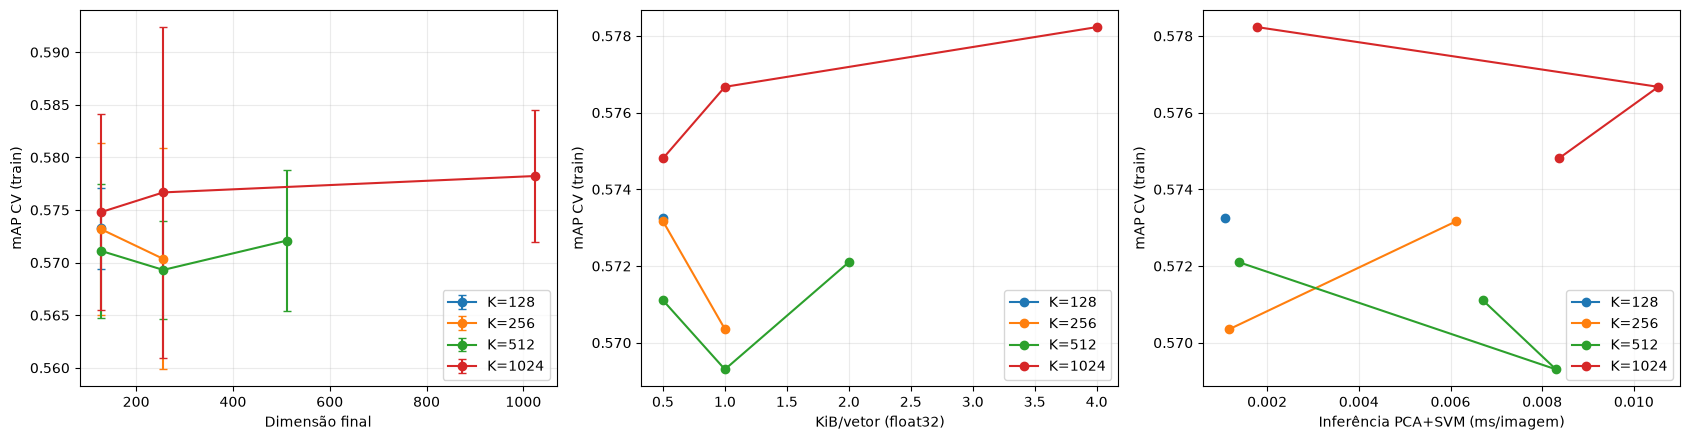

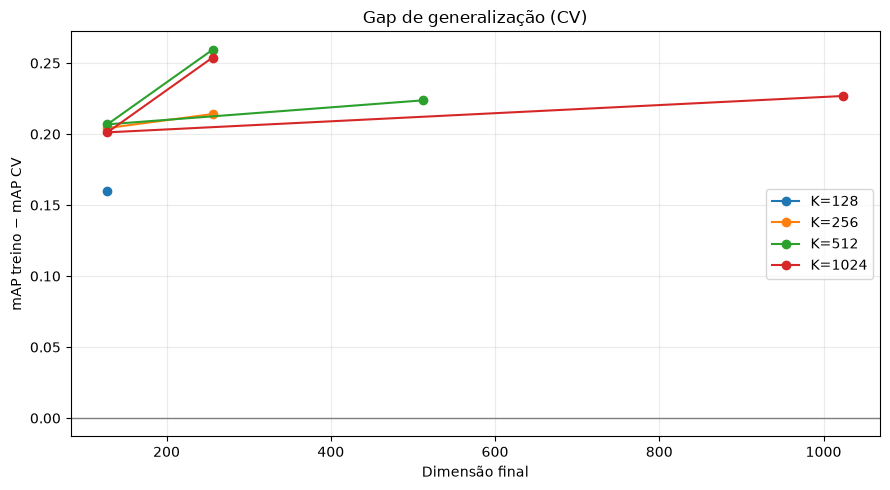

Tabelas .csv e .tex, figuras e manifestos: C:\Users\guilh\Desktop\Mestrado\2ºAno\CVC\Assig#1\iacv_labs\assignment2\code\results\part3_complete
Nota: métricas CV não são estimativas de um teste independente.


In [10]:
fig,axs=plt.subplots(1,3,figsize=(17,4.5))
for k,grp in part3_comparison.groupby("K"):
    grp=grp.sort_values("dimensions")
    axs[0].errorbar(grp.dimensions,grp.mAP_mean,yerr=grp.mAP_std,marker="o",capsize=3,label=f"K={k}")
    axs[1].plot(grp.feature_KiB_float32,grp.mAP_mean,"o-",label=f"K={k}")
    axs[2].plot(grp.inference_ms_per_image,grp.mAP_mean,"o-",label=f"K={k}")
for ax,xlabel in zip(axs,["Dimensão final","KiB/vetor (float32)","Inferência PCA+SVM (ms/imagem)"]):
    ax.set(xlabel=xlabel,ylabel="mAP CV (train)");ax.grid(alpha=.25);ax.legend()
fig.tight_layout();fig.savefig(PART3_OUTPUT/"cv_tradeoffs.png",dpi=170);plt.show()
fig,ax=plt.subplots(figsize=(9,5))
for k,grp in part3_comparison.groupby("K"):
    ax.plot(grp.dimensions,grp.train_minus_cv_mAP,"o-",label=f"K={k}")
ax.axhline(0,color="gray",linewidth=1);ax.set(xlabel="Dimensão final",ylabel="mAP treino − mAP CV",title="Gap de generalização (CV)")
ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(PART3_OUTPUT/"cv_generalization_gap.png",dpi=170);plt.show()
print("Tabelas .csv e .tex, figuras e manifestos:",PART3_OUTPUT.resolve())
print("Nota: métricas CV não são estimativas de um teste independente.")